<a href="https://colab.research.google.com/github/gaaj-ufrpe/pisi_adam/blob/main/pisi_adam_eda_ml_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
None

--- First 5 rows ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


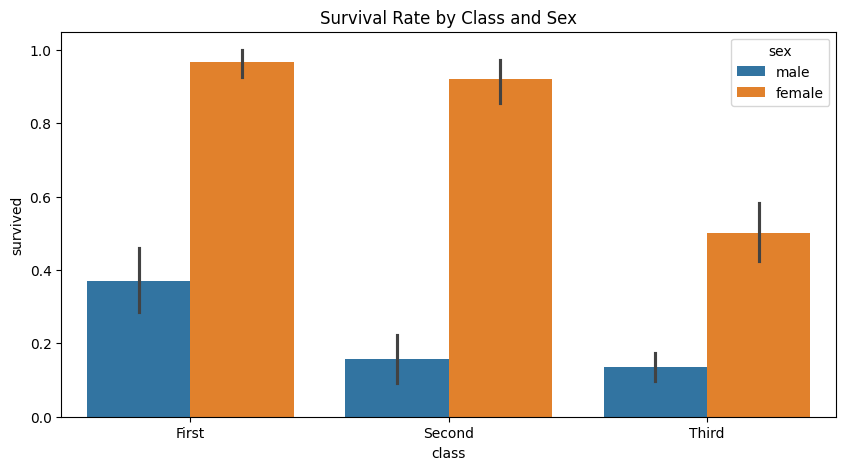


--- Model Performance ---
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       105
           1       0.80      0.76      0.78        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



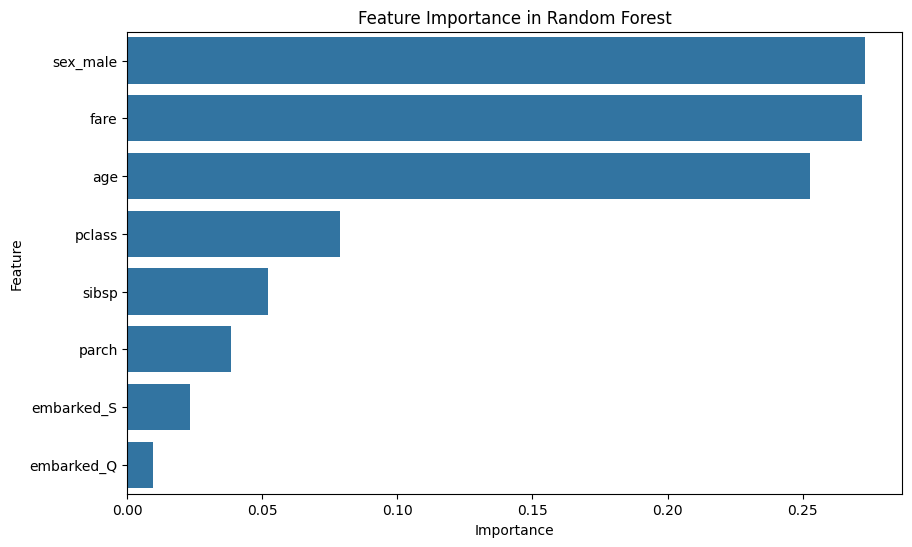

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load the dataset
df = sns.load_dataset('titanic')

# 2. Basic EDA
print("--- Dataset Info ---")
print(df.info())
print("\n--- First 5 rows ---")
display(df.head())

# Visualization: Survival rate by class and sex
plt.figure(figsize=(10, 5))
sns.barplot(x='class', y='survived', hue='sex', data=df)
plt.title('Survival Rate by Class and Sex')
plt.show()

# 3. Data Preprocessing
# Dropping columns with too many missing values or redundant info
# survived is the target. 'alive' is a duplicate. 'who', 'adult_male', 'deck' etc.
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
X = df[features].copy()
y = df['survived']

# Handling missing values
X['age'] = X['age'].fillna(X['age'].median())
X['embarked'] = X['embarked'].fillna(X['embarked'].mode()[0])

# Categorical encoding
X = pd.get_dummies(X, columns=['sex', 'embarked'], drop_first=True)

# 4. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Random Forest Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 6. Evaluation
y_pred = rf_model.predict(X_test)
print("\n--- Model Performance ---")
print(classification_report(y_test, y_pred))

# 7. Feature Importance
importances = rf_model.feature_importances_
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title('Feature Importance in Random Forest')
plt.show()

### Análise Exploratória Adicional
Vamos visualizar a distribuição de idade, tarifas e a correlação entre as variáveis numéricas.

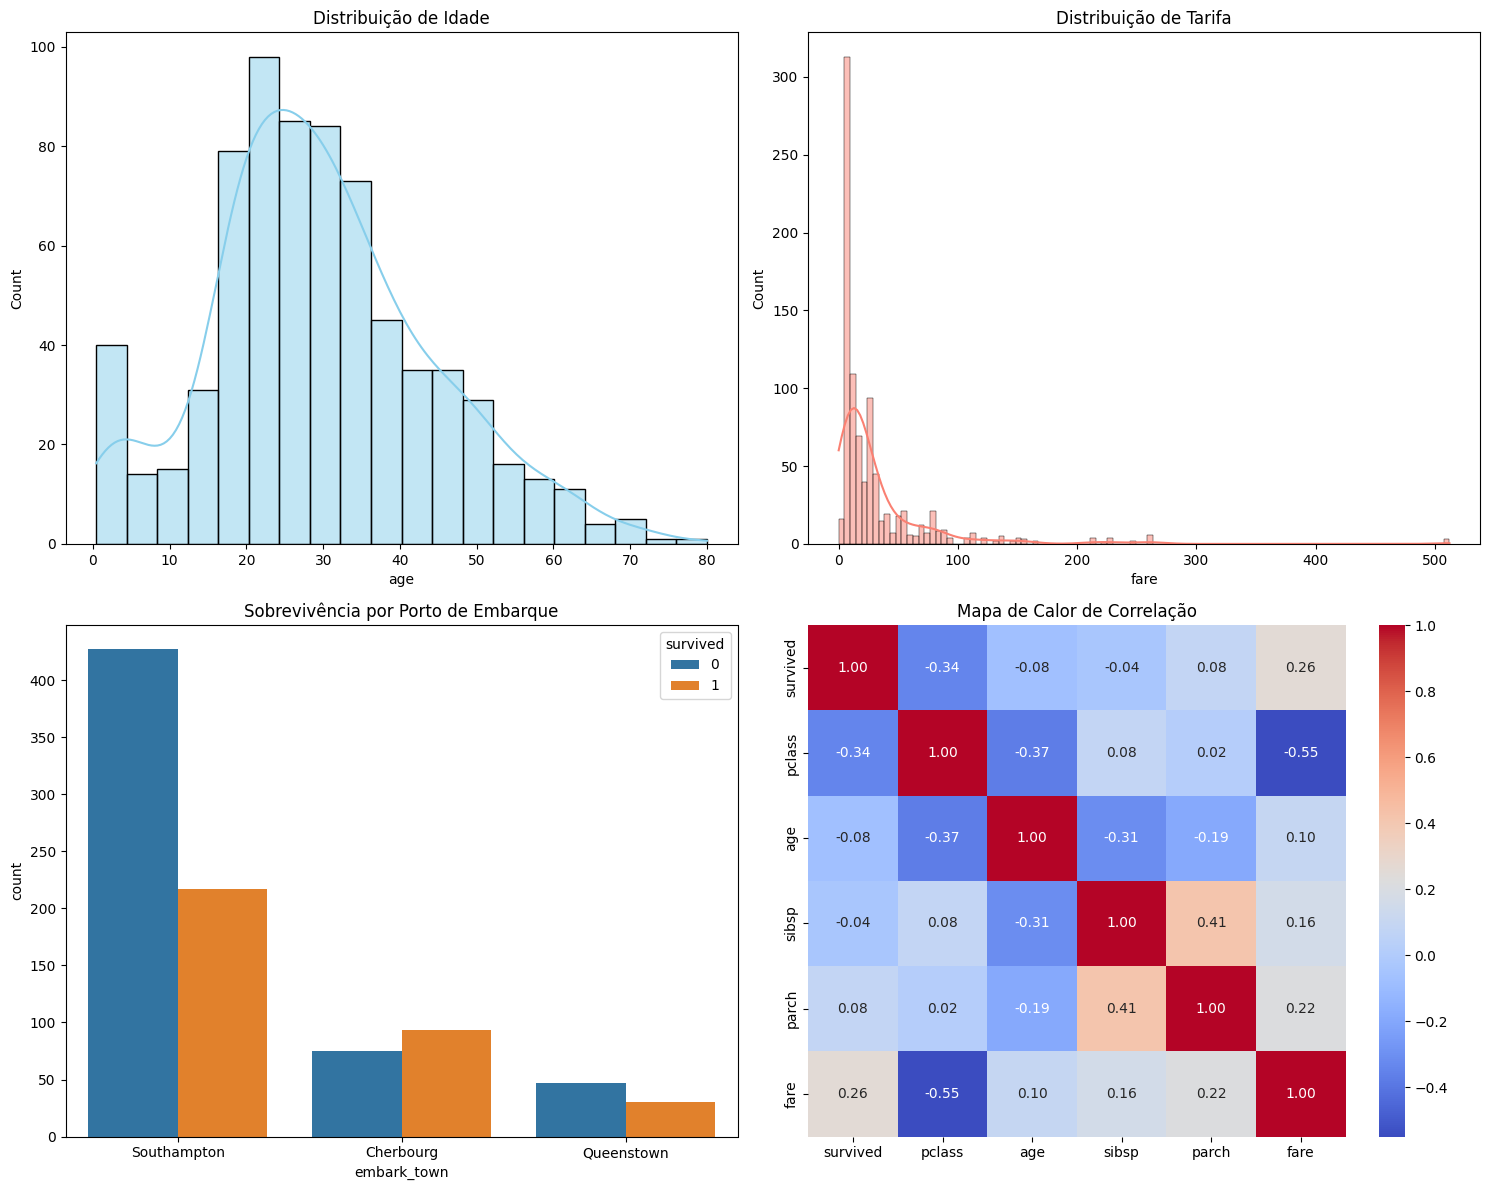

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# Criando uma figura com múltiplos subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Distribuição de Idade
sns.histplot(df['age'].dropna(), kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribuição de Idade')

# 2. Distribuição de Tarifa (Fare)
sns.histplot(df['fare'], kde=True, ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Distribuição de Tarifa')

# 3. Sobrevivência por Porto de Embarque
sns.countplot(x='embark_town', hue='survived', data=df, ax=axes[1, 0])
axes[1, 0].set_title('Sobrevivência por Porto de Embarque')

# 4. Mapa de Calor de Correlação
corr = df.select_dtypes(include=['number']).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1, 1])
axes[1, 1].set_title('Mapa de Calor de Correlação')

plt.tight_layout()
plt.show()

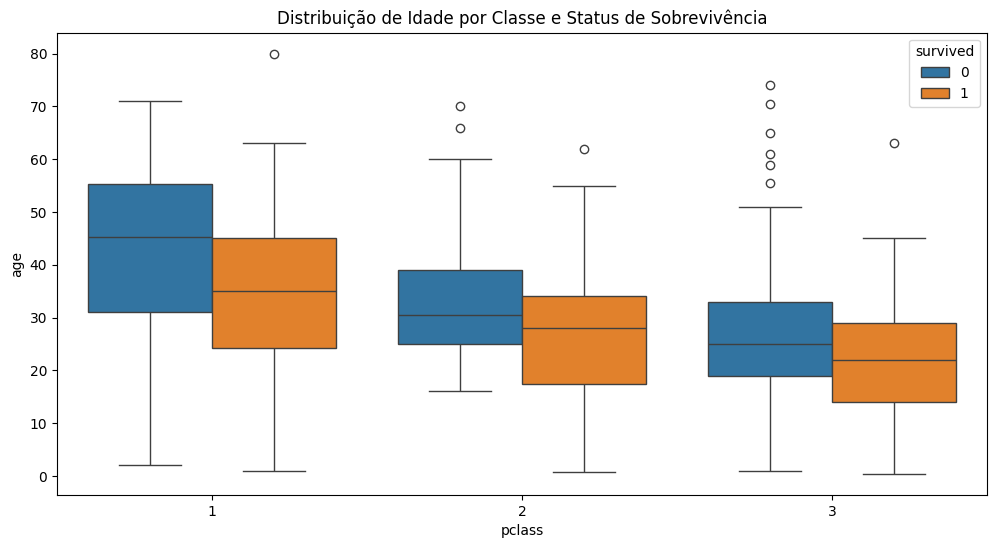

In [3]:
# Boxplot para ver a relação entre Classe, Idade e Sobrevivência
plt.figure(figsize=(12, 6))
sns.boxplot(x='pclass', y='age', hue='survived', data=df)
plt.title('Distribuição de Idade por Classe e Status de Sobrevivência')
plt.show()

### Comparação de Modelos Preditivos
Vamos testar diferentes algoritmos para ver qual se adapta melhor aos dados do Titanic.

--- Tabela Comparativa de Métricas ---


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:59:44] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,Random Forest,0.821229,0.800000,0.756757,0.777778,0.886873
2,SVC,0.821229,0.838710,0.702703,0.764706,0.860746
0,Logistic Regression,0.810056,0.785714,0.743243,0.763889,0.881982
4,XGBoost,0.804469,0.767123,0.756757,0.761905,0.879665
5,KNN,0.804469,0.782609,0.729730,0.755245,0.854247
3,Gradient Boosting,0.804469,0.819672,0.675676,0.740741,0.880952


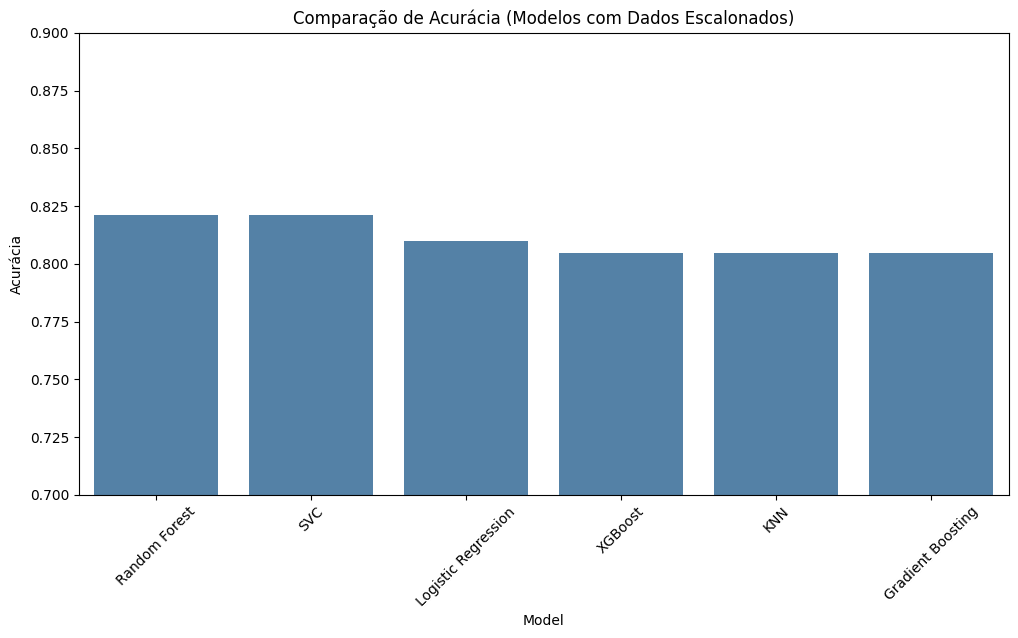

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Escalonamento dos dados (essencial para KNN e SVC)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Dicionário de modelos atualizado
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVC': SVC(probability=True, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    'KNN': KNeighborsClassifier()
}

metrics_list = []

# Treino e avaliação
for name, model in models.items():
    # Modelos baseados em distância/gradiente usam dados escalonados
    if name in ['Logistic Regression', 'SVC', 'KNN']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

    metrics_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

# Criar DataFrame de métricas
metrics_df = pd.DataFrame(metrics_list).sort_values(by='F1-Score', ascending=False)

# Exibir tabela comparativa
print("--- Tabela Comparativa de Métricas ---")
display(metrics_df.style.highlight_max(axis=0, color='lightgreen'))

# Comparação visual de Acurácia corrigindo o warning do hue
plt.figure(figsize=(12, 6))
sns.barplot(x='Model', y='Accuracy', data=metrics_df, color='steelblue')
plt.ylim(0.7, 0.9)
plt.title('Comparação de Acurácia (Modelos com Dados Escalonados)')
plt.ylabel('Acurácia')
plt.xticks(rotation=45)
plt.show()

### Detalhamento por Classe (Survived vs Died)
Para entender onde cada modelo está errando, vamos visualizar as métricas discriminadas por classe.

In [6]:
from sklearn.metrics import classification_report

for name, model in models.items():
    print(f"\n{'='*30}")
    print(f"Modelo: {name}")
    print(f"{'='*30}")

    if name in ['Logistic Regression', 'SVC', 'KNN']:
        y_pred_temp = model.predict(X_test_scaled)
    else:
        y_pred_temp = model.predict(X_test)

    print(classification_report(y_test, y_pred_temp, target_names=['Died (0)', 'Survived (1)']))


Modelo: Logistic Regression
              precision    recall  f1-score   support

    Died (0)       0.83      0.86      0.84       105
Survived (1)       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179


Modelo: Random Forest
              precision    recall  f1-score   support

    Died (0)       0.83      0.87      0.85       105
Survived (1)       0.80      0.76      0.78        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179


Modelo: SVC
              precision    recall  f1-score   support

    Died (0)       0.81      0.90      0.86       105
Survived (1)       0.84      0.70      0.76        74

    accuracy                           0.82       179
   macro avg       0.83      0.80      0.81       179
weighted 

### Comparativo Final: Desempenho por Classe
Esta tabela resume o F1-Score (média harmônica entre Precisão e Recall) para cada classe em todos os modelos, ajudando a identificar qual algoritmo é mais equilibrado.

In [8]:
from sklearn.metrics import f1_score

comparison_data = []

for name, model in models.items():
    if name in ['Logistic Regression', 'SVC', 'KNN']:
        y_pred_temp = model.predict(X_test_scaled)
    else:
        y_pred_temp = model.predict(X_test)

    comparison_data.append({
        'Modelo': name,
        'Precision (Died 0)': precision_score(y_test, y_pred_temp, pos_label=0),
        'Precision (Survived 1)': precision_score(y_test, y_pred_temp, pos_label=1),
        'Recall (Died 0)': recall_score(y_test, y_pred_temp, pos_label=0),
        'Recall (Survived 1)': recall_score(y_test, y_pred_temp, pos_label=1),
        'F1-Score (Died 0)': f1_score(y_test, y_pred_temp, pos_label=0),
        'F1-Score (Survived 1)': f1_score(y_test, y_pred_temp, pos_label=1),
        'Acurácia Global': accuracy_score(y_test, y_pred_temp)
    })

final_comp_df = pd.DataFrame(comparison_data).sort_values(by='Acurácia Global', ascending=False)

display(final_comp_df.style.highlight_max(axis=0, color='lightgreen'))

print(f"\nO melhor modelo em termos de Acurácia e equilíbrio entre as classes foi o {final_comp_df.iloc[0]['Modelo']}.")

,Modelo,Precision (Died 0),Precision (Survived 1),Recall (Died 0),Recall (Survived 1),F1-Score (Died 0),F1-Score (Survived 1),Acurácia Global
1,Random Forest,0.834862,0.800000,0.866667,0.756757,0.850467,0.777778,0.821229
2,SVC,0.811966,0.838710,0.904762,0.702703,0.855856,0.764706,0.821229
0,Logistic Regression,0.825688,0.785714,0.857143,0.743243,0.841121,0.763889,0.810056
3,Gradient Boosting,0.796610,0.819672,0.895238,0.675676,0.843049,0.740741,0.804469
4,XGBoost,0.830189,0.767123,0.838095,0.756757,0.834123,0.761905,0.804469
5,KNN,0.818182,0.782609,0.857143,0.729730,0.837209,0.755245,0.804469



O melhor modelo em termos de Acurácia e equilíbrio entre as classes foi o Random Forest.
